## Loading MNIST

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
import copy
import random
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# download and load MNIST from pytorch
# normalize with standard MNIST mean and std
transform_base = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# for augmentation
transform_aug = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])


full_train_base = datasets.MNIST(root='./data', train=True, download=True, transform=transform_base)
full_train_aug = datasets.MNIST(root='./data', train=True, download=True, transform=transform_aug)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform_base)

# check train/test size
print(len(full_train_base), len(test_dataset))

60000 10000


## Train/validation set split with/without augmentation, keep test set unchanged

In [2]:
# split original train set into train and validation
gen = torch.Generator().manual_seed(42)
train_subset_base, val_subset_base = random_split(full_train_base, [50000, 10000], generator=gen)

# split original train set with augmentation
gen = torch.Generator().manual_seed(42)
train_subset_aug, val_subset_aug = random_split(full_train_aug, [50000, 10000], generator=gen)

val_subset_base.dataset = copy.copy(full_train_base)
val_subset_base.dataset.transform = transform_base

val_subset_aug.dataset = copy.copy(full_train_aug)
val_subset_aug.dataset.transform = transform_base

train_loader_base = DataLoader(train_subset_base, batch_size=64, shuffle=True)
train_loader_aug = DataLoader(train_subset_aug, batch_size=64, shuffle=True)

val_loader_base = DataLoader(val_subset_base, batch_size=1000, shuffle=False)
val_loader_aug = DataLoader(val_subset_aug, batch_size=1000, shuffle=False)

test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

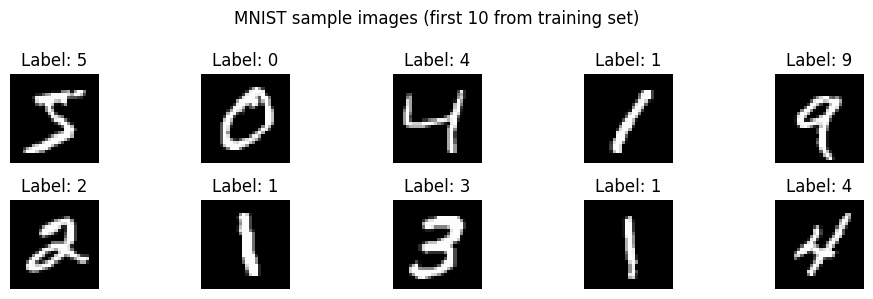

In [3]:
# view first 10 training image examples
mean, std = 0.1307, 0.3081
fig, axes = plt.subplots(2, 5, figsize=(10, 3))
for i, ax in enumerate(axes.flat):
    img, label = full_train_base[i]
    ax.imshow((img * std + mean).squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("MNIST sample images (first 10 from training set)")
plt.tight_layout()
plt.show()

## Three models setup (MLP, CNN, Transformer)

In [4]:
# create three models:
# 1. a shallow Multi-Layer Perceptron (MLP)
# 2. a Convolutional Neural Network (CNN)
# 3. a Transformer (Encoder)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(32 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)
        )
    def forward(self, x): return self.net(x)

class Transformer_Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_size = 7
        self.embed_dim = 64
        self.patch_proj = nn.Linear(7 * 7, self.embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, self.embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 16 + 1, self.embed_dim))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)


        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.embed_dim,
            nhead=4,
            dim_feedforward=256,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
            )
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=2,
            norm=nn.LayerNorm(self.embed_dim),
            enable_nested_tensor=False
            )
        self.head = nn.Linear(self.embed_dim, 10)

    def forward(self, x):
        B = x.shape[0]
        patches = x.unfold(2, self.patch_size, self.patch_size).unfold(3, self.patch_size, self.patch_size)
        patches = patches.contiguous().view(B, 16, -1)
        x = self.patch_proj(patches)
        x = torch.cat((self.cls_token.expand(B, -1, -1), x), dim=1) + self.pos_embed
        return self.head(self.transformer(x)[:, 0, :])

## Training Prep

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def train_and_eval(model, train_loader, val_loader, test_loader, name, epochs=15):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    print(f"\n--- Training {name} ---")
    for epoch in range(epochs):
        # training model
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0

        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            outputs = model(bx)
            loss = criterion(outputs, by)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * bx.size(0)
            _, predicted = torch.max(outputs, 1)
            total_train += by.size(0)
            correct_train += (predicted == by).sum().item()

        history['train_loss'].append(running_loss / total_train)
        history['train_acc'].append(correct_train / total_train)

        # validation
        model.eval()
        running_val_loss, correct_val, total_val = 0.0, 0, 0

        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                outputs = model(bx)
                loss = criterion(outputs, by)

                running_val_loss += loss.item() * bx.size(0)
                _, predicted = torch.max(outputs, 1)
                total_val += by.size(0)
                correct_val += (predicted == by).sum().item()

        history['val_loss'].append(running_val_loss / total_val)
        history['val_acc'].append(correct_val / total_val)

        print(f"Epoch {epoch+1}/{epochs} | Train Acc: {history['train_acc'][-1]*100:.2f}% | Val Acc: {history['val_acc'][-1]*100:.2f}%")

    model.eval()
    all_probs = []
    all_targets = []
    correct_test, total_test = 0, 0

    with torch.no_grad():
        for bx, by in test_loader:
            bx, by = bx.to(device), by.to(device)
            outputs = model(bx)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)

            total_test += by.size(0)
            correct_test += (predicted == by).sum().item()

            all_probs.append(probs.cpu().numpy())
            all_targets.append(by.cpu().numpy())

    print(f"--> {name} Final Test Accuracy: {(correct_test/total_test)*100:.2f}%")

    all_probs = np.vstack(all_probs)
    all_targets = np.concatenate(all_targets)
    return all_probs, all_targets, history

## Training models

In [6]:
# initialize models
models = {'MLP': MLP, 'CNN': CNN, 'Transformer': Transformer_Encoder}

results_probs = {}
results_history = {}
targets_for_eval = None

for name, model_class in models.items():
    # training without augmentation
    model_base = model_class()
    probs_base, targets_base, hist_base = train_and_eval(
        model=model_base,
        train_loader=train_loader_base,
        val_loader=val_loader_base,
        test_loader=test_loader,
        name=f"{name} (No Aug)"
    )

    # store results for non-augmentation
    results_probs[f"{name} (No Aug)"] = probs_base
    results_history[f"{name} (No Aug)"] = hist_base

    # training with augmentation
    model_aug = model_class()
    probs_aug, targets_aug, hist_aug = train_and_eval(
        model=model_aug,
        train_loader=train_loader_aug,
        val_loader=val_loader_aug,
        test_loader=test_loader,
        name=f"{name} (With Aug)"
    )

    # store results for augmentation
    results_probs[f"{name} (With Aug)"] = probs_aug
    results_history[f"{name} (With Aug)"] = hist_aug

    # test on the same testing test
    targets_for_eval = targets_base


--- Training MLP (No Aug) ---
Epoch 1/15 | Train Acc: 92.52% | Val Acc: 96.12%
Epoch 2/15 | Train Acc: 96.91% | Val Acc: 96.74%
Epoch 3/15 | Train Acc: 97.79% | Val Acc: 97.06%
Epoch 4/15 | Train Acc: 98.39% | Val Acc: 96.99%
Epoch 5/15 | Train Acc: 98.59% | Val Acc: 97.38%
Epoch 6/15 | Train Acc: 98.89% | Val Acc: 97.41%
Epoch 7/15 | Train Acc: 99.10% | Val Acc: 97.25%
Epoch 8/15 | Train Acc: 99.17% | Val Acc: 97.36%
Epoch 9/15 | Train Acc: 99.25% | Val Acc: 97.42%
Epoch 10/15 | Train Acc: 99.36% | Val Acc: 97.58%
Epoch 11/15 | Train Acc: 99.39% | Val Acc: 97.52%
Epoch 12/15 | Train Acc: 99.37% | Val Acc: 97.75%
Epoch 13/15 | Train Acc: 99.51% | Val Acc: 97.62%
Epoch 14/15 | Train Acc: 99.39% | Val Acc: 97.69%
Epoch 15/15 | Train Acc: 99.62% | Val Acc: 97.56%
--> MLP (No Aug) Final Test Accuracy: 97.98%

--- Training MLP (With Aug) ---
Epoch 1/15 | Train Acc: 84.24% | Val Acc: 94.70%
Epoch 2/15 | Train Acc: 93.11% | Val Acc: 96.23%
Epoch 3/15 | Train Acc: 94.27% | Val Acc: 96.91%
Epo

## Training performance evaluation

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

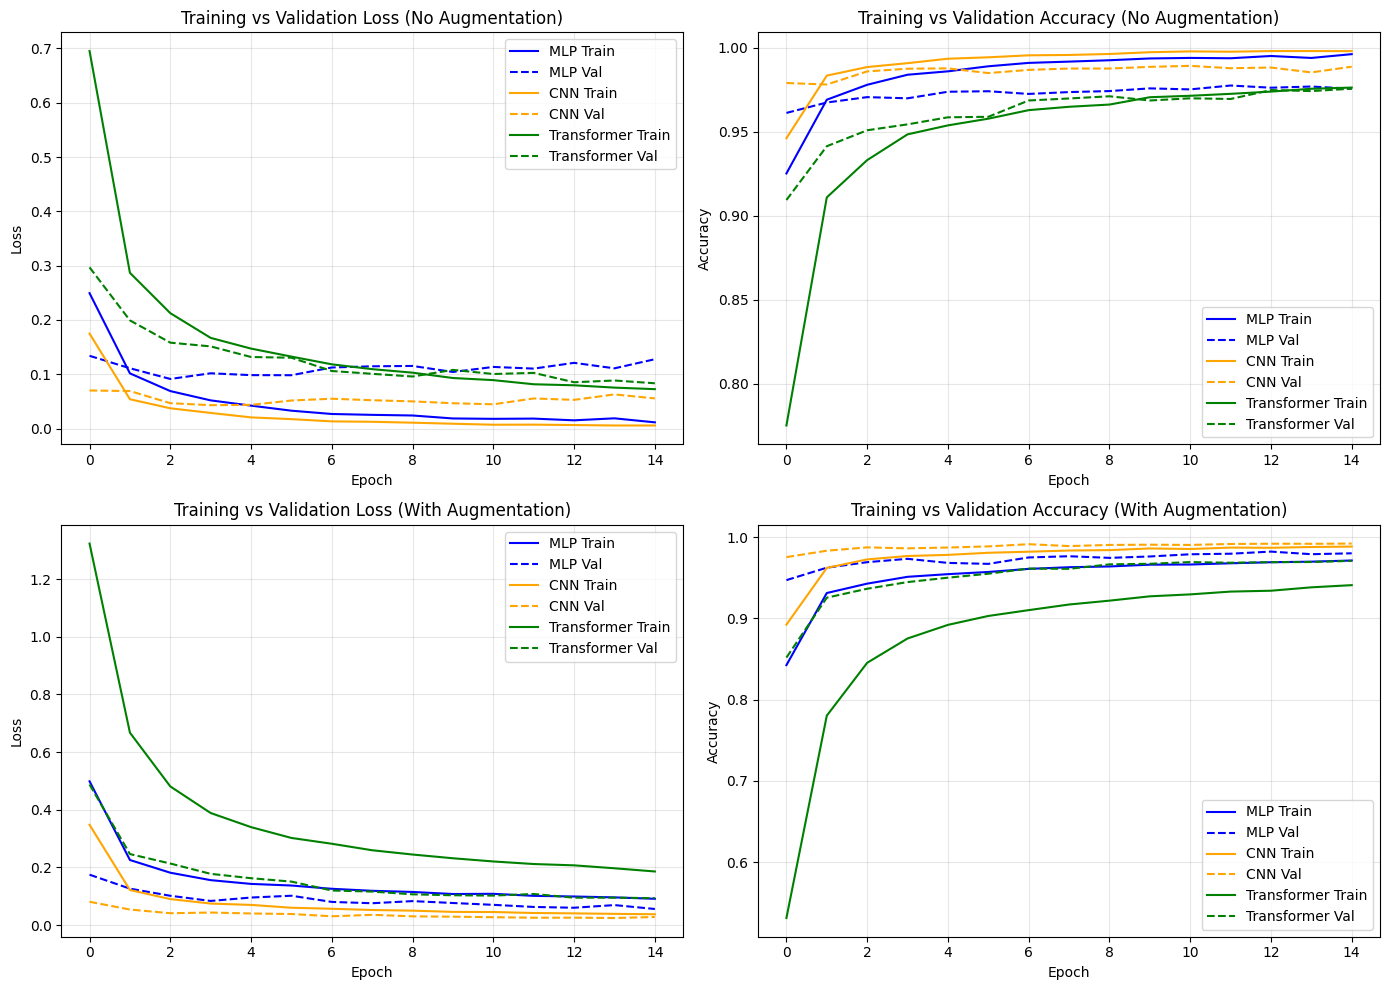

In [7]:
# from google.colab import files
# define colors for models
colors = {'MLP': 'blue', 'CNN': 'orange', 'Transformer': 'green'}

# training performance plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
(ax1, ax2), (ax3, ax4) = axes

# plots for non-augmentation
for name, hist in results_history.items():
    if "(No Aug)" in name:
        base_name = name.split(" (")[0]
        ax1.plot(hist['train_loss'], label=f'{base_name} Train', color=colors[base_name], linestyle='-')
        ax1.plot(hist['val_loss'], label=f'{base_name} Val', color=colors[base_name], linestyle='--')

        ax2.plot(hist['train_acc'], label=f'{base_name} Train', color=colors[base_name], linestyle='-')
        ax2.plot(hist['val_acc'], label=f'{base_name} Val', color=colors[base_name], linestyle='--')

ax1.set_title('Training vs Validation Loss (No Augmentation)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.set_title('Training vs Validation Accuracy (No Augmentation)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

# plots for augmentation
for name, hist in results_history.items():
    if "(With Aug)" in name:
        base_name = name.split(" (")[0]
        ax3.plot(hist['train_loss'], label=f'{base_name} Train', color=colors[base_name], linestyle='-')
        ax3.plot(hist['val_loss'], label=f'{base_name} Val', color=colors[base_name], linestyle='--')

        ax4.plot(hist['train_acc'], label=f'{base_name} Train', color=colors[base_name], linestyle='-')
        ax4.plot(hist['val_acc'], label=f'{base_name} Val', color=colors[base_name], linestyle='--')

ax3.set_title('Training vs Validation Loss (With Augmentation)')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Loss')
ax3.legend()
ax3.grid(True, alpha=0.3)

ax4.set_title('Training vs Validation Accuracy (With Augmentation)')
ax4.set_xlabel('Epoch')
ax4.set_ylabel('Accuracy')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('train_performance.png', dpi=300, bbox_inches='tight')
# files.download('train_performance.png')
plt.show()

## Testing performance evaluation

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

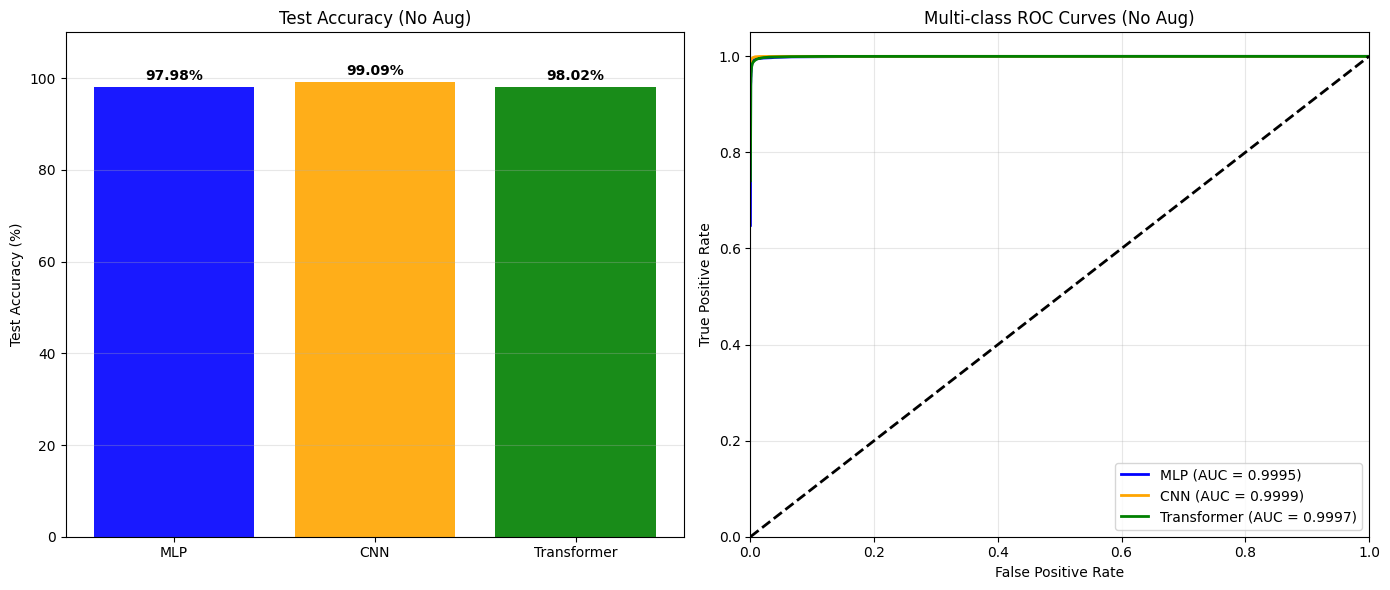

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

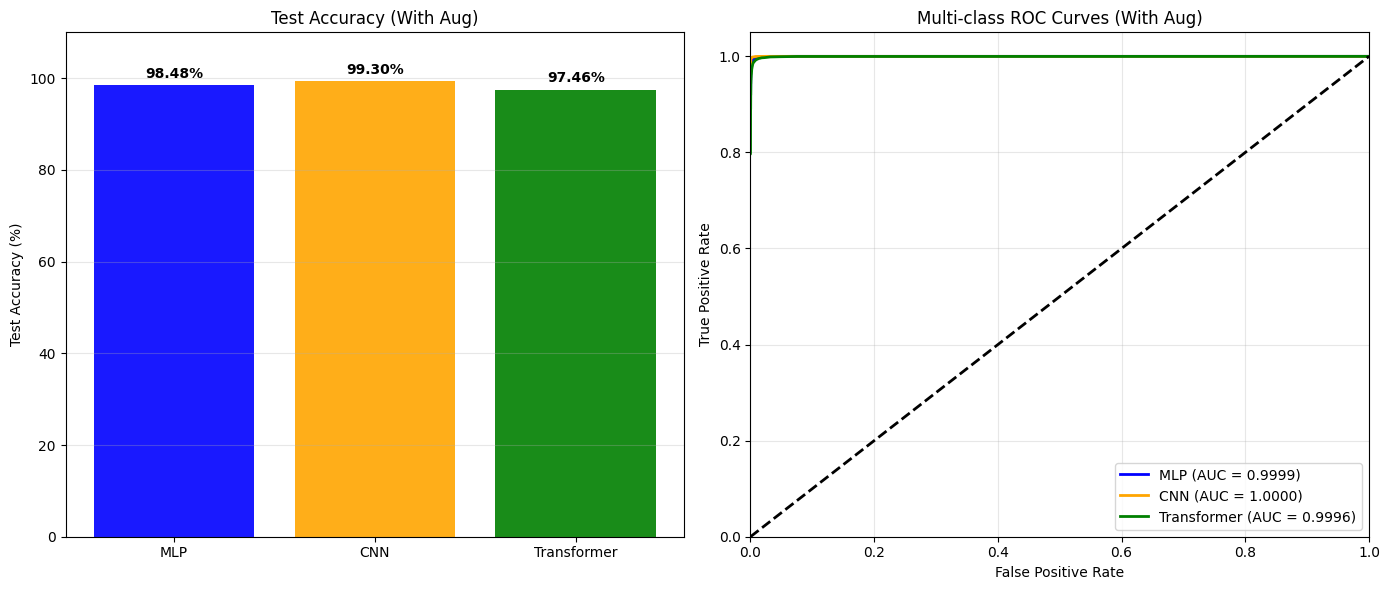

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

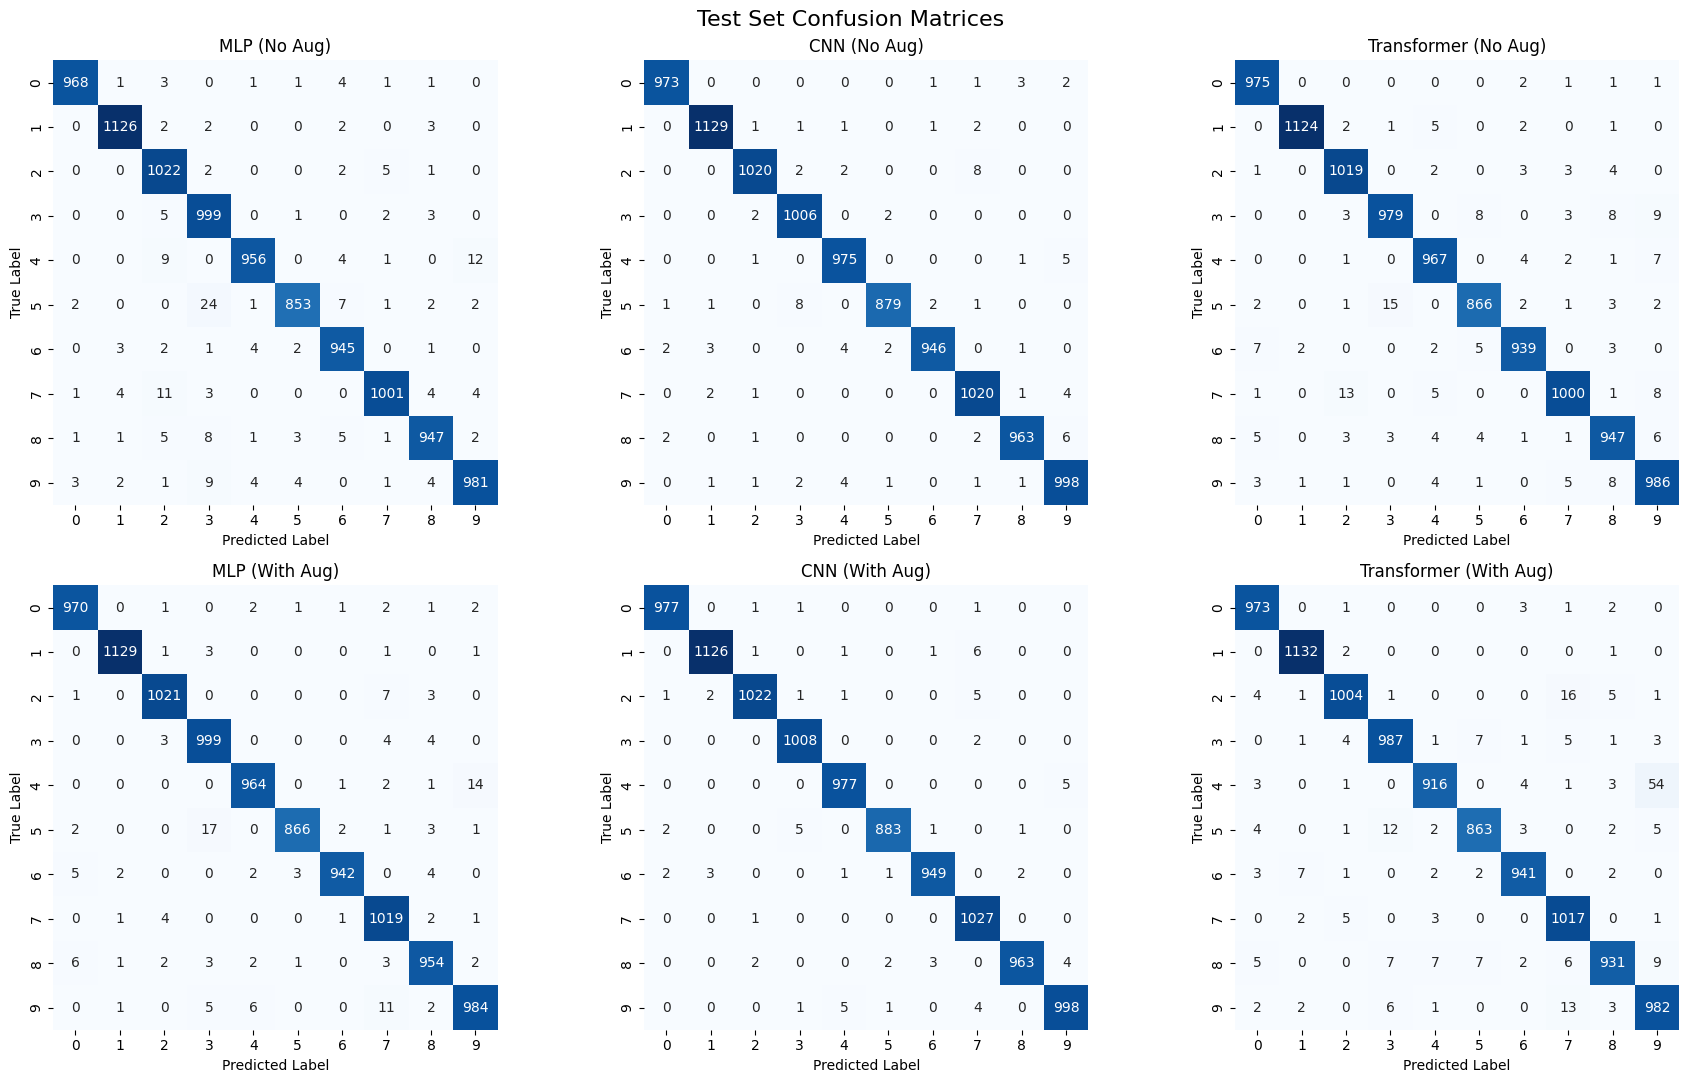

In [8]:
# plots for testing set performance
y_test_bin = label_binarize(targets_for_eval, classes=range(10))

def plot_test_performance(condition_suffix, filename):
    filtered_probs = {k: v for k, v in results_probs.items() if condition_suffix in k}

    # calculate test accuracies
    accuracies = {}
    for name, probs in filtered_probs.items():
        preds = np.argmax(probs, axis=1)
        acc = np.mean(preds == targets_for_eval) * 100
        accuracies[name.split(" ")[0]] = acc

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # bar graph for accuracy
    model_names = list(accuracies.keys())
    acc_values = list(accuracies.values())
    bar_colors = [colors[name] for name in model_names]

    bars = ax1.bar(model_names, acc_values, color=bar_colors, alpha=0.9)
    for bar in bars:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.2f}%',
                 ha='center', va='bottom', fontweight='bold', fontsize=10)

    ax1.set_ylim(0, 110)
    ax1.set_ylabel('Test Accuracy (%)')
    ax1.set_title(f'Test Accuracy {condition_suffix}')
    ax1.grid(axis='y', alpha=0.3)

    # auc curve
    for name, probs in filtered_probs.items():
        base_name = name.split(" ")[0]
        fpr, tpr = dict(), dict()
        for i in range(10):
            fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], probs[:, i])

        all_fpr = np.unique(np.concatenate([fpr[i] for i in range(10)]))
        mean_tpr = np.zeros_like(all_fpr)
        for i in range(10):
            mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
        mean_tpr /= 10

        macro_auc = auc(all_fpr, mean_tpr)
        ax2.plot(all_fpr, mean_tpr, lw=2, color=colors[base_name], label=f'{base_name} (AUC = {macro_auc:.4f})')

    ax2.plot([0, 1], [0, 1], 'k--', lw=2)
    ax2.set_xlim([0.0, 1.0])
    ax2.set_ylim([0.0, 1.05])
    ax2.set_xlabel('False Positive Rate')
    ax2.set_ylabel('True Positive Rate')
    ax2.set_title(f'Multi-class ROC Curves {condition_suffix}')
    ax2.legend(loc="lower right")
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    # files.download(filename)
    plt.show()


plot_test_performance('(No Aug)', 'test_performance_no_augmentation.png')
plot_test_performance('(With Aug)', 'test_performance_augmentation.png')

# confusion matrix
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

plot_order = [
    ['MLP (No Aug)', 'CNN (No Aug)', 'Transformer (No Aug)'],
    ['MLP (With Aug)', 'CNN (With Aug)', 'Transformer (With Aug)']
]

for row_idx in range(2):
    for col_idx in range(3):
        model_name = plot_order[row_idx][col_idx]
        probs = results_probs[model_name]

        preds = np.argmax(probs, axis=1)
        cm = confusion_matrix(targets_for_eval, preds, labels=range(10))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[row_idx, col_idx],
                    cbar=False, annot_kws={"size": 10}, square=True)

        axes[row_idx, col_idx].set_title(f'{model_name}')
        axes[row_idx, col_idx].set_xlabel('Predicted Label')
        axes[row_idx, col_idx].set_ylabel('True Label')

plt.suptitle('Test Set Confusion Matrices', fontsize=16)
plt.tight_layout()
plt.savefig("Confusion_Matrix.png", dpi=300, bbox_inches='tight')
# files.download("Confusion_Matrix.png")

plt.show()

In [9]:
import json
from sklearn.metrics import precision_score, recall_score, f1_score

# save training performance stats to json file
with open('train_performance_stats.json', 'w') as f:
    json.dump(results_history, f, indent=4)

# files.download('train_performance_stats.json')

# save test set statistics
test_stats = {}

for name, probs in results_probs.items():
    # accuracy
    preds = np.argmax(probs, axis=1)
    acc = float(np.mean(preds == targets_for_eval) * 100)

    # precision, recall, f1 scores
    prec = float(precision_score(targets_for_eval, preds, average='macro', zero_division=0))
    rec = float(recall_score(targets_for_eval, preds, average='macro', zero_division=0))
    f1 = float(f1_score(targets_for_eval, preds, average='macro', zero_division=0))

    # marco auc
    fpr, tpr = dict(), dict()
    for i in range(10):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], probs[:, i])

    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(10)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(10):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= 10

    macro_auc = float(auc(all_fpr, mean_tpr))


    test_stats[name] = {
        'test_accuracy_percent': round(acc, 2),
        'macro_auc': round(macro_auc, 4),
        'macro_precision': round(prec, 4),
        'macro_recall': round(rec, 4),
        'macro_f1': round(f1, 4)
    }

with open('test_performance_stats.json', 'w') as f:
    json.dump(test_stats, f, indent=4)

#files.download('test_performance_stats.json')

print("JSON train/test statistics files saved.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

JSON train/test statistics files saved.
